In [9]:
# Prompt Chaining
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv
load_dotenv()
import os

In [10]:
model=ChatGroq(
    model="qwen/qwen3.8-27b",
    api_key=os.getenv("GROQ_API_KEY"),
    max_tokens=300
)

In [ ]:
class BlogState(TypedDict):
    title:str
    outline:str
    content:str
    evaluate_score:int

In [12]:
def create_outline(state:BlogState)->BlogState:
    # fetch title
    title=state["title"]
    
    # call LLM gen outline
    prompt=f"Generate the 1 line outline for a blog on the topic-{title}"
    
    outline=model.invoke(prompt).content
    
    # update state
    state["outline"]=outline
    
    # return state
    return state

In [13]:
def create_blog(state:BlogState)->BlogState:
    title=state["title"]
    outline=state["outline"]
    prompt=f"write a small blog in 3 lines on the title-{title} using the following outline-\n{outline}"
    
    content=model.invoke(prompt).content
    state["content"]=content
    return state

In [18]:
def evaluate(state:BlogState)->BlogState:
    content=state["content"]
    prompt=f"Give an integer score out of 1 to 10 for blog on the basis of depth of thoughts,clarity of ideas,strong opinion,grammer etc-{content}"
    evaluate_score=model.invoke(prompt).content
    state["evaluate_score"]=evaluate_score
    return state

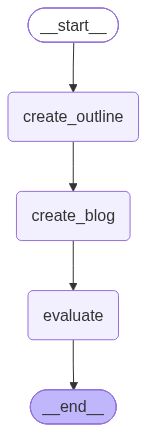

In [20]:
graph=StateGraph(BlogState)

# nodes
graph.add_node('create_outline',create_outline)
graph.add_node('create_blog',create_blog)
graph.add_node('evaluate',evaluate)
# edges
graph.add_edge(START,'create_outline')
graph.add_edge('create_outline','create_blog')
graph.add_edge('create_blog','evaluate')
graph.add_edge('evaluate',END)

workflow=graph.compile()
graph.compile()

In [15]:
initial_state={"title":"Rise of AI in India"}
final_state=workflow.invoke(initial_state)
print(final_state)
print(final_state["content"])
print(final_state["outline"])

{'title': 'Rise of AI in India', 'outline': 'From grassroots innovation to national policy, explore how India is accelerating its journey to become a global leader in artificial intelligence.', 'content': 'India is witnessing a surge in grassroots innovation that is rapidly transforming local challenges into global AI solutions. This momentum is now being amplified by robust national policies designed to foster a supportive ecosystem for technology and talent. Together, these efforts are propelling the nation on an accelerated path to becoming a recognized global leader in artificial intelligence.'}
India is witnessing a surge in grassroots innovation that is rapidly transforming local challenges into global AI solutions. This momentum is now being amplified by robust national policies designed to foster a supportive ecosystem for technology and talent. Together, these efforts are propelling the nation on an accelerated path to becoming a recognized global leader in artificial intellig

In [16]:
print(final_state["outline"])

From grassroots innovation to national policy, explore how India is accelerating its journey to become a global leader in artificial intelligence.


In [17]:
print(final_state["content"])

India is witnessing a surge in grassroots innovation that is rapidly transforming local challenges into global AI solutions. This momentum is now being amplified by robust national policies designed to foster a supportive ecosystem for technology and talent. Together, these efforts are propelling the nation on an accelerated path to becoming a recognized global leader in artificial intelligence.
